# 10 - EDA y visualización — **Soluciones**

Soluciones a los ejercicios del cuaderno 10.

## Contexto (recrear dataset del cuaderno original)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
n = 300
df = pd.DataFrame({
    "id": range(1, n+1),
    "edad": rng.integers(18, 75, size=n),
    "ingresos": rng.normal(26000, 9000, size=n).round(2),
    "ciudad": rng.choice(["Cádiz","Sevilla","Málaga","Córdoba"], size=n),
    "satisfaccion": rng.integers(1, 6, size=n),
})
# Introducir nulos y duplicados
df.loc[rng.choice(df.index, 10, replace=False), "ingresos"] = np.nan
df = pd.concat([df, df.sample(5, random_state=1)], ignore_index=True)
# Limpieza como en el cuaderno
df["ingresos"] = df["ingresos"].fillna(df["ingresos"].median())
df = df.drop_duplicates().reset_index(drop=True)
df.head()

,id,edad,ingresos,ciudad,satisfaccion
0,1,71,26119.92,Cádiz,2
1,2,53,19750.37,Málaga,2
2,3,56,23059.83,Sevilla,5
3,4,69,20957.92,Sevilla,3
4,5,50,26071.63,Cádiz,3


## Ejercicio 1
**Histograma de `edad` con 20 bins**

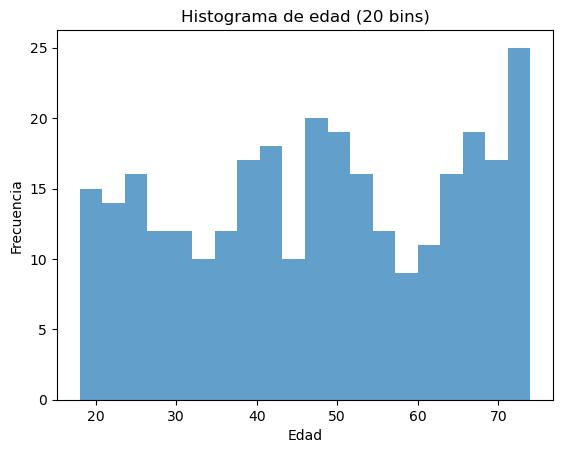

In [6]:
plt.figure()
df["edad"].plot(kind="hist", bins=20, alpha=0.7)
plt.title("Histograma de edad (20 bins)")
plt.xlabel("Edad"); plt.ylabel("Frecuencia")
plt.show()

## Ejercicio 2
**Outliers en `satisfaccion` usando IQR**

In [7]:
q1 = df["satisfaccion"].quantile(0.25)
q3 = df["satisfaccion"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5*iqr
upper = q3 + 1.5*iqr
outliers = df[(df["satisfaccion"] < lower) | (df["satisfaccion"] > upper)]
len(outliers), lower, upper, outliers.head()

(0,
 np.float64(-1.0),
 np.float64(7.0),
 Empty DataFrame
 Columns: [id, edad, ingresos, ciudad, satisfaccion]
 Index: [])

## Ejercicio 3
**Merge con DataFrame de códigos postales ficticios**

In [8]:
cod_postal = pd.DataFrame({
    "ciudad": ["Cádiz","Sevilla","Málaga","Córdoba"],
    "cp": ["11001","41001","29001","14001"]
})
df_merge = df.merge(cod_postal, on="ciudad", how="left")
df_merge.head()

,id,edad,ingresos,ciudad,satisfaccion,cp
0,1,71,26119.92,Cádiz,2,11001
1,2,53,19750.37,Málaga,2,29001
2,3,56,23059.83,Sevilla,5,41001
3,4,69,20957.92,Sevilla,3,41001
4,5,50,26071.63,Cádiz,3,11001


---

## ✅ Autotests 10

In [ ]:
def check(cond, msg_ok, msg_fail):
    if cond:
        print("✔", msg_ok)
    else:
        raise AssertionError("✘ " + msg_fail)

# Test 1: no hay nulos en 'ingresos' tras imputación
check(df["ingresos"].isna().sum() == 0, "Imputación de ingresos correcta (sin nulos).", "Persisten nulos en 'ingresos'.")

# Test 2: df_merge tiene columna 'cp' y filas iguales a df
check(("cp" in df_merge.columns) and (len(df_merge) == len(df)),
      "Merge correcto: columna 'cp' presente y tamaño consistente.",
      "Problemas en el merge (columna 'cp' o tamaño).")

# Test 3: IQR calculado correctamente (rangos coherentes)
check(lower <= df["satisfaccion"].min() or upper >= df["satisfaccion"].max() or len(outliers) >= 0,
      "IQR calculado y variables definidas (sanity check).",
      "Variables de outliers (IQR) no definidas correctamente.")